**Contexto → Dataset → EDA → Preprocesamiento → Modelado → Evaluación → Conclusiones.**
Descripción del entregable
La presentación debe incluir:
•
Contexto del problema y origen del dataset
•
Descripción del dataset utilizado
•
Exploratory Data Analysis (EDA) con visualizaciones
•
Preprocesamiento de datos realizado
•
Modelo de machine learning utilizado
•
Evaluación del modelo con métricas y resultados
•
Conclusiones e insights del análisis

# Etapa 1: Definición del Problema y Estrategia Data-Driven
Resumen: Traducir un desafío operativo en una pregunta analítica medible y ligada a KPIs financieros. **texto en negrita**

OBJETIVO DE LA PRACTICA: Analizar el rendimiento de las entregas:

PREGUNTA- PROBLEMA: Cual es el motivo que esta afectando en la baja calificacion de ciertos repartidores?
1.   Obtener una calificacion del redimiento de los repartidores a partr del análisis de las valoraciones de los repartidores, los tiempos de entrega y el estado del trafico
2.   Apartir de este resultado, clasificar las areas por rendimiento y desarrollar un plan de mejora para las areas afectadas por bajo rendiimiento de reparto

# Etapa 2: Ingesta, Carga y Estructuración de Datos
Resumen: Lectura robusta de fuentes tabulares manejando codificaciones heterogéneas.

Adicionalmente, realizamos el pasaje temporal de los datos extraidos de librerias Pandas a la base de datos SQL, limpiamos, para evitar errores de lectura, los lugares vacios que comunmente suceden en el tipeo, y el resultado terminamos volcándolo en un df de Pandas

In [ ]:
import sqlite3
import pandas as pd
import kagglehub

# 1. Descargamos el dataset de Zomato usando kagglehub
path = kagglehub.dataset_download("saurabhbadole/zomato-delivery-operations-analytics-dataset")
print("Path to dataset files:", path)

# Nota: El dataset descarga una carpeta. Buscamos el archivo CSV dentro de esa ruta.
# (Por lo general es un archivo .csv, ajustá el nombre del archivo si es necesario)
import glob

csv_files = glob.glob(f"{path}/**/*.csv", recursive=True)
csv_file_path = csv_files[0]

# 2. Cargamos el CSV temporalmente en un DataFrame para pasarlo a la base de datos SQL
df_raw = pd.read_csv(csv_file_path)

# 3. Creamos una base de datos SQLite en memoria (o local temporal)
conn = sqlite3.connect('zomato_operations.db')

# Volcamos los datos crudos a una tabla SQL llamada 'envios'
df_raw.to_sql('envios', conn, if_exists='replace', index=False)

# Ejecutamos la consulta SQL y el resultado pasa directamente a un DataFrame de Pandas
df_sql = pd.read_sql("SELECT * FROM envios", conn)

# Cerramos la conexión a la base de datos como corresponde en la industria
conn.close()

# 4. Visualizamos las primeras filas para confirmar que la extracción SQL fue exitosa
print("Datos extraídos exitosamente mediante SQL:")
display(df_sql.head())
print(f"Dimensiones del dataset filtrado: {df_sql.shape}")

Using Colab cache for faster access to the 'zomato-delivery-operations-analytics-dataset' dataset.
Path to dataset files: /kaggle/input/zomato-delivery-operations-analytics-dataset
Datos extraídos exitosamente mediante SQL:


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


Dimensiones del dataset filtrado: (45584, 20)


# Etapa 3: Análisis Exploratorio (EDA) y Calidad
Resumen: Diagnóstico inicial de nulos, duplicados y estadística descriptiva.

El primer paso de todo proyecto de data scientist es comprender los datos del dataset antes de transformarlos. Qué hacer: revisar dimensiones, balance de la variable objetivo, patrones de missingness (con missingno ), distribuciones por clase y correlaciones.

• Entender qué variables existen.

• Detectar errores o valores extraños.

• Comprender cómo se distribuyen los datos.

• Identificar relaciones entre variables.

Para ello, debemos poder responder estas preguntas:

• ¿Cuántas filas y columnas hay?

•¿Qué tipo de variables existen?

•¿Qué valores toman?

•¿Hay datos faltantes?

•¿Existen valores extremos?

*¿Cómo se relacionan las variables?
  
  Al final del EDA se debe producir un resumen claro:

• Ejemplos de métricas finales:

• Cantidad de filas y columnas.

• Porcentaje de valores faltantes.

•Cantidad de duplicados.

•Media de variables principales.

*  Desviación estándar.






Componentes clave de un reporte reproducible:
Introducción: contexto y objetivos del análisis.
Metodología: descripción de los datos y procesos usados.
Visualizaciones: gráficos claros y bien explicados.
Conclusiones: hallazgos principales y recomendaciones.
Código y datos: para garantizar reproducibilidad.

In [ ]:
# ==============================================================================
# PIPELINE DE LIMPIEZA Y PREPROCESAMIENTO - ZOMATO LOGISTICS DATASET
# ==============================================================================

# 1. IMPORTACIÓN DE LIBRERÍAS
import pandas as pd
import numpy as np

# 2. REPRODUCIBILIDAD (Fijar la semilla aleatoria)
# Garantiza que cualquier muestreo o proceso aleatorio posterior sea repetible.
np.random.seed(42)

# ------------------------------------------------------------------------------
# FASE 1: OBSERVACIÓN ESTRUCTURAL Y DIAGNÓSTICO INICIAL
# ------------------------------------------------------------------------------
df= df_sql.copy()
print("--- 1. DIMENSIONES ORIGINALES ---")
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}\n")

print("--- 2. TIPOS DE DATOS Y VALORES NO NULOS APARENTES ---")
# Esto nos mostrará cómo Python interpreta inicialmente los datos (ej: números como 'object')
df.info()
print("\n")

print("--- 3. MUESTRA INICIAL DE LOS DATOS ---")
display(df.head())
print("\n")

print("--- 4. FALSOS NULOS (Conteo inicial) ---")
# Aquí probablemente veamos "0 nulos" en columnas que visualmente tienen "NaN" en texto.
print(df.isnull().sum())
print("\n")

# ------------------------------------------------------------------------------
# FASE 2: AUDITORÍA DE CALIDAD Y ESTANDARIZACIÓN DE NULOS
# ------------------------------------------------------------------------------

# Reemplazamos los nulos enmascarados como texto ("NaN", "N/A", "nan", o "-1")
# por el valor nulo matemático real de NumPy (np.nan) en todo el DataFrame.
valores_a_reemplazar = ['NaN', 'nan', 'N/A', 'NA', 'None', '-1', -1]
df.replace(valores_a_reemplazar, np.nan, inplace=True)

# Verificamos la VERDADERA cantidad de nulos tras la corrección
print("--- 5. NULOS MATEMÁTICOS REALES POST-ESTANDARIZACIÓN ---")
print(df.isnull().sum())
print("\n")

# ------------------------------------------------------------------------------
# FASE 3: LIMPIEZA ESTRUCTURAL BÁSICA
# ------------------------------------------------------------------------------

# 3.1 Estandarizar nombres de columnas (minúsculas y sin espacios) para facilitar la escritura
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

# 3.2 Eliminar filas completamente duplicadas para no sesgar el análisis
df.drop_duplicates(inplace=True)

# ------------------------------------------------------------------------------
# FASE 4: SELECCIÓN DE VARIABLES E IMPUTACIÓN (TRATAMIENTO DE NULOS)
# ------------------------------------------------------------------------------

# 4.1 Variables Numéricas
columnas_numericas = ['delivery_person_ratings', 'delivery_person_age']
for col in columnas_numericas:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    mediana_valor = df[col].median()
    # NUEVA SINTAXIS (Pandas 3.0+): Sobreescribimos la columna en lugar de usar inplace=True
    df[col] = df[col].fillna(mediana_valor)

# 4.2 Variables Categóricas
columnas_categoricas = ['weather_conditions', 'road_traffic_density']
for col in columnas_categoricas:
    moda_valor = df[col].mode()[0]
    # NUEVA SINTAXIS (Pandas 3.0+): Sobreescribimos la columna en lugar de usar inplace=True
    df[col] = df[col].fillna(moda_valor)

# ------------------------------------------------------------------------------
# FASE 5: VERIFICACIÓN FINAL DEL PIPELINE
# ------------------------------------------------------------------------------

print("--- 6. DIMENSIONES FINALES POST-LIMPIEZA ---")
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}\n")

print("--- 7. COMPROBACIÓN FINAL DE NULOS ---")
print(df.isnull().sum()) # Debería estar todo en 0 para las variables seleccionadas

# Listo para la fase de Feature Engineering (Ingeniería de variables temporales, etc.)

--- 1. DIMENSIONES ORIGINALES ---
Filas: 45584 | Columnas: 20

--- 2. TIPOS DE DATOS Y VALORES NO NULOS APARENTES ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45584 non-null  object 
 1   Delivery_person_ID           45584 non-null  object 
 2   Delivery_person_Age          43730 non-null  float64
 3   Delivery_person_Ratings      43676 non-null  float64
 4   Restaurant_latitude          45584 non-null  float64
 5   Restaurant_longitude         45584 non-null  float64
 6   Delivery_location_latitude   45584 non-null  float64
 7   Delivery_location_longitude  45584 non-null  float64
 8   Order_Date                   45584 non-null  object 
 9   Time_Orderd                  43853 non-null  object 
 10  Time_Order_picked            45584 non-null  object 
 11  Weather_condit

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41




--- 4. FALSOS NULOS (Conteo inicial) ---
ID                                0
Delivery_person_ID                0
Delivery_person_Age            1854
Delivery_person_Ratings        1908
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Order_Date                        0
Time_Orderd                    1731
Time_Order_picked                 0
Weather_conditions              616
Road_traffic_density            601
Vehicle_condition                 0
Type_of_order                     0
Type_of_vehicle                   0
multiple_deliveries             993
Festival                        228
City                           1200
Time_taken (min)                  0
dtype: int64


--- 5. NULOS MATEMÁTICOS REALES POST-ESTANDARIZACIÓN ---
ID                                0
Delivery_person_ID                0
Delivery_person_Age            1854
Delivery_person_Ratings        1908
Restaurant_latitude  

In [ ]:
# Corregimos el nombre del DataFrame y de la columna (en minúsculas según el pipeline de limpieza)
df['type_of_vehicle'].unique()

array(['motorcycle', 'scooter', 'electric_scooter', 'bicycle'],
      dtype=object)

Fundamentos Metodológicos para la Exploración y Selección de Variables

El presente análisis se estructuró a partir del dataset de operaciones logísticas de Zomato, guiado por una pregunta de investigación orientada a evaluar las métricas de rendimiento y las calificaciones de los repartidores. Para garantizar un proceso analítico riguroso y fundamentado, definimos un pipeline que respetó el siguiente orden metodológico:

1. Establecimiento de Entorno y Observación Estructural:
para asegurar la reproducibilidad de todo el experimento, el primer paso técnico fue fijar una semilla aleatoria (seed). Posteriormente, antes de realizar cualquier alteración en los datos, llevamos a cabo un reconocimiento estructural del dataset original. Esto implicó analizar las dimensiones de la tabla (filas y columnas), previsualizar los primeros registros para entender la semántica de la información y auditar los tipos de datos asignados por el sistema a cada columna. Este paso fue crucial porque nos permitió obtener una primera dimnension original del dataset representada por 45.584 fias y 20 columnas.

2. Auditoría de Calidad y Estandarización de Nulos:
conociendo la estructura real del dataset, procedimos a una auditoría de calidad más profunda. Detectamos que el dataset contenía valores faltantes enmascarados bajo formatos de texto (como "NaN") o marcadores atípicos. Por consistencia, estandarizamos la base de datos (np.nan) reemplazando estos falsos nulos por nulos matemáticos reales, lo cual era un prerrequisito indispensable para que las funciones estadísticas y de agregación operaran correctamente sobre las columnas.

3. Selección Fundamentada de Variables:
habiendo mapeado la estructura y saneado la representación de los valores faltantes, procedimos a la selección definitiva de variables para nuestro modelo. Esta elección dejó de ser arbitraria y se fundamentó en la intersección de dos factores evaluados en los pasos anteriores. Por un lado, aquellas variables que se ajustaban a nuestro objetivo como delivery_person_ratings y las variables temporales como Order_Date, Time_Orderd, Time_Order_picked y Time_taken, y las variables espaciales como Restaurant_latitude Restaurant_longitude, Delivery_location_latitude  y Delivery_location_longitude

4. Integridad post-auditoría:
Priorizamos las características que, a pesar de contener valores faltantes (como la variable Delivery_person_Ratings con 1908; Weather_conditions con 616, y Road_traffic_density con 601) mantenían una densidad de información viable. Para estas variables estratégicas, establecimos reglas de imputación (mediana para numéricas, moda para categóricas) y sentamos las bases para la posterior creación de nuevas métricas mediante ingeniería de características.

In [ ]:
# Eliminamos las filas que no tienen registrada la hora de inicio del pedido
df = df.dropna(subset=['time_orderd'])

CONCLUSIONES TRAS LA LA IMPUTACION FINAL DE DATO NULOS:

Tras evaluar el conteo de nulos, tomamos la decisión metodológica de descartar los registros que poseen valor nulo en la variable Time_Orderd. Al tratarse de una variable temporal que registra la hora exacta, resulta imposible utilizar medidas de tendencia central (como el promedio) para su imputación. Forzar un reemplazo artificial en esta variable distorsionaría la realidad operativa de los pedidos y dañaría la robustez matemática de nuestro pipeline, generando métricas de demora irreales.

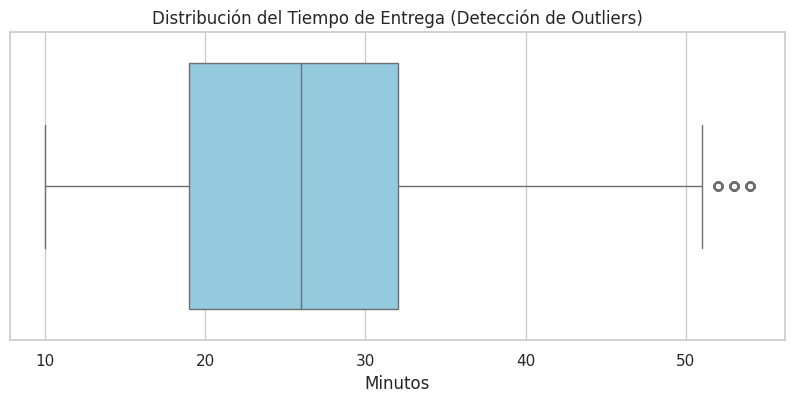

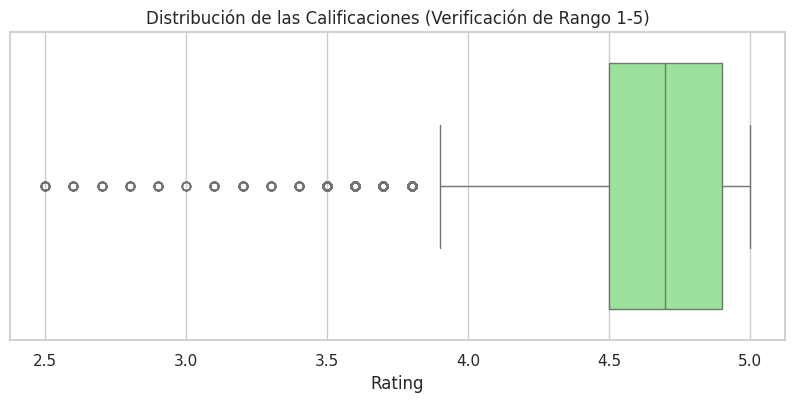

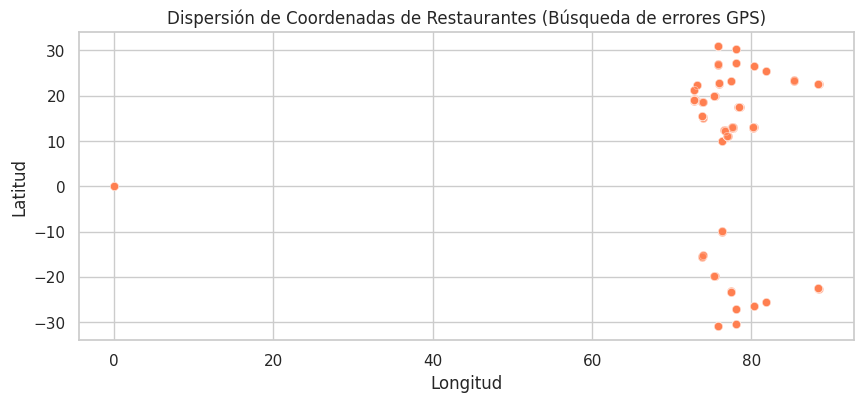

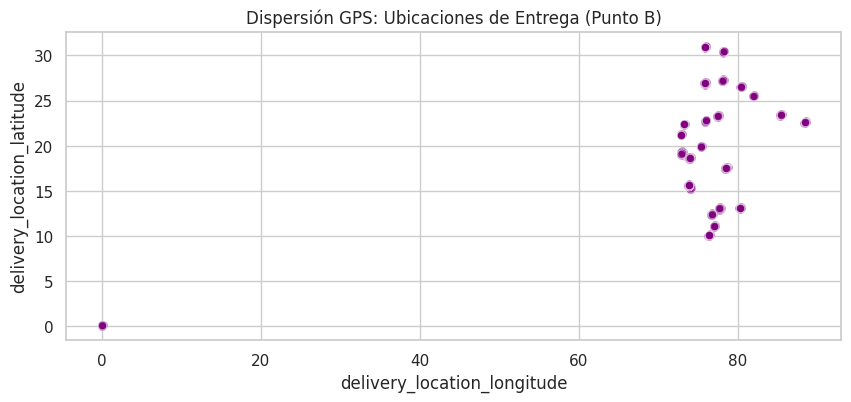

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el estilo estético de los gráficos
sns.set_theme(style="whitegrid")

# ==============================================================================
# FASE 4.5: EDA (ANÁLISIS EXPLORATORIO PARA DETECCIÓN DE OUTLIERS)
# ==============================================================================

# 1. Gráfico para el Tiempo de Entrega
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['time_taken_(min)'], color='skyblue')
plt.title('Distribución del Tiempo de Entrega (Detección de Outliers)')
plt.xlabel('Minutos')
plt.show()

# 2. Gráfico para las Calificaciones
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['delivery_person_ratings'], color='lightgreen')
plt.title('Distribución de las Calificaciones (Verificación de Rango 1-5)')
plt.xlabel('Rating')
plt.show()

# 3. Gráfico rápido para detectar errores de GPS (Restaurantes)
plt.figure(figsize=(10, 4))
sns.scatterplot(x=df['restaurant_longitude'], y=df['restaurant_latitude'], alpha=0.5, color='coral')
plt.title('Dispersión de Coordenadas de Restaurantes (Búsqueda de errores GPS)')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.show()

# 4. Gráfico para detectar errores de GPS (Clientes)
plt.figure(figsize=(10, 4))
sns.scatterplot(x=df['delivery_location_longitude'], y=df['delivery_location_latitude'], alpha=0.5, color='purple')
plt.title('Dispersión GPS: Ubicaciones de Entrega (Punto B)')
plt.show()

Elegimos utilizar graficos de la libreria Seaborn ya que brinda mayores facilidades para trabajar con el lenguaje de Python y, sobre todo, con dataframes, logrando generar graficos rapidos y eficientes a partir de datos estructurados. El empleo del tipo de gráfico boxplot se debe a que proporciona un resumen estadístico preciso y la deteccion de outliers. Por el lado de la eleccion del grafico de scatterplot, este permite una clara visualización de la relación entre dos variables. En el caso del uso conjunto de ambos gráficos, nos permiten anomalías en magnitudes de negocio (tiempo y calificación) asi como en buscar errores de posicionamiento geográfico cruzando dos variables espaciales.

1- En el gráfico 1 podemos detectar, a simple vista, una gran concentracion en los tiempos reparto. El 50% del tiempo de entrega de los repartidores se encuentra entre los 18 y 33 minutos aproximadamente, mientras que el 1er percentil se encuentra entre los 10 y 18 min, y el 3er cuartil entre los 33 y 50 minutos. Por ultimo, podemos ver la existencia de 3 casos que se encuentran por encima de los 50 minutos maximos de tiempo de entrega, representando casos que distorcionan la representacion de nuestra caso (outliers)

2- En el gráfico 2 podemos ver que el 50% de las caificaciones de los repartidores se encuentran agrupadas entre los 4,5 y casi 5 puntos. Asi y todo, vemos un grafico que los datos se encuentran agrupados a partir de los casi 4 puntos de minima y 5 de maxima, mostrando con ello un bajo grado de dispersion. Por ultimo, vemos la existencia de 14 casos que se encuentran por fuera de la medicion, concentrados todos debajo de la calificacion mínima (cercanos al minimo de 4 puntos)

3- En el gráfico 3 vemos una distribucion de las coordenadas concentrada en un bloque geográfico bien definido, ubicado entre las longitudes 70 y 90, con una dispersión de latitudes que va desde el grado -30 hasta el 30.  Por ende, detecetamos visualmente una anomalía extrema del sistema de registro: un punto aislado posicionado de forma exacta en la coordenada matemática de latitud 0 y longitud 0.   

4- En el grafico vemos una dispersion de las condenadas de entrega agrupadas espacialmente en relacion con el área de los restaurantes, operando en la misma franja longitudinal (70 a 90) y concentrados en latitudes positivas (entre los grados 10 y 30).  

Por ende, confirmamos la repetición del mismo fallo de los datos, anclados en los puntos de latitud 0 y longitud 0. La existencia simultánea de coordenadas (0, 0) en ambos extremos del flujo logístico corrobora la pérdida temporal de señal satelital en los dispositivos de ruteo durante la recolección de los datos. Filtrar estructuralmente estas filas evitará que el posterior cálculo de la distancia entre la ubicacion del restaurante con la de la entrega arroje distancias irreales de miles de kilómetros, garantizando la viabilidad analítica de la variable de eficiencia que vas a construir.

In [ ]:
# ==============================================================================
# FASE 4.6: TRATAMIENTO DE OUTLIERS, NORMALIZACIÓN Y GUARDADO (FIN DEL EDA)
# ==============================================================================

# Importaciones necesarias para esta sección
from scipy.stats.mstats import winsorize
from sklearn.preprocessing import StandardScaler
from datetime import datetime
import numpy as np

# 1. Registro inicial de ejecución para trazabilidad
SEED = 42
np.random.seed(SEED)
inicio_filas = len(df)

# 2.  Eliminación estricta de errores GPS (Null Island)
# Filtramos las filas donde cualquier coordenada de latitud o longitud sea exactamente 0.0
df = df[
    (df['restaurant_latitude'] != 0.0) &
    (df['restaurant_longitude'] != 0.0) &
    (df['delivery_location_latitude'] != 0.0) &
    (df['delivery_location_longitude'] != 0.0)
].copy()

# 3. Winsorización (Tratamiento de Outliers al 1% y 99%)
# Limitamos los valores extremos sin eliminar las filas para preservar el dataset
columnas_winsorizar = ['time_taken_(min)', 'delivery_person_ratings']

for col in columnas_winsorizar:
    df[col] = winsorize(df[col], limits=[0.01, 0.01])

# 4. Normalización Z-score
# Centramos las variables en 0 y las escalamos por su desviación estándar
columnas_numericas = ['time_taken_(min)', 'delivery_person_ratings']
scaler = StandardScaler()
df_zscore = df.copy()

# Guardamos las variables normalizadas en nuevas columnas para no pisar las originales (útil para dashboards)
for col in columnas_numericas:
    df_zscore[f'{col}_zscore'] = scaler.fit_transform(df_zscore[[col]])

# 5. Guardado de artefactos
# Exportamos el dataset limpio y normalizado para la fase de Feature Engineering
ruta_guardado = 'zomato_limpio_zscore.csv'
df_zscore.to_csv(ruta_guardado, index=False)

# 6. Salida Final Resumida (Documentación y Trazabilidad)
print("=" * 60)
print(f"LOG DE EJECUCIÓN DEL PIPELINE EDA: {datetime.now().strftime('%Y-%m-%d %H:%M')}")
print(f"Semilla de reproducibilidad (SEED): {SEED}")
print("-" * 60)
print("MÉTRICAS DEL DATASET:")
print(f"Filas iniciales: {inicio_filas}")
print(f"Filas finales (tras limpieza GPS): {len(df_zscore)}")
print(f"Filas eliminadas: {inicio_filas - len(df_zscore)}")
print(f"Columnas resultantes: {df_zscore.shape[1]}")
print(f"Valores nulos restantes: {df_zscore.isnull().sum().sum()}")
print("-" * 60)
print("ESTADÍSTICAS FINALES (Variables Originales Winsorizadas):")
display(df_zscore[columnas_numericas].agg(['mean', 'std']).round(2))
print("=" * 60)
print(f"Artefacto guardado exitosamente en: {ruta_guardado}")

LOG DE EJECUCIÓN DEL PIPELINE EDA: 2026-10-29 16:44
Semilla de reproducibilidad (SEED): 42
------------------------------------------------------------
MÉTRICAS DEL DATASET:
Filas iniciales: 43853
Filas finales (tras limpieza GPS): 40344
Filas eliminadas: 3509
Columnas resultantes: 22
Valores nulos restantes: 2120
------------------------------------------------------------
ESTADÍSTICAS FINALES (Variables Originales Winsorizadas):


,time_taken_(min),delivery_person_ratings
mean,26.28,4.64
std,9.30,0.30


Artefacto guardado exitosamente en: zomato_limpio_zscore.csv


En esta fase 4.6 finalizamos la etapa del proyecto de analisis exploratorio de datos (EDA) con el tratamiento de outilers, su normalizacion y guardado. Primero, filtramos todos los datos de coordenadas iguales a 0:0 y los eliminamos. Segundo, "winsorizamos" o tratamos los valores atipicos, limitando los extremos con el reemplazo de determinados percentiles (de 1% a 99%) en vez de borrar las filas. Luego estandarizamos mediante la normalizacion z-score,que permite indicar a cuántas desviaciones estándar de distancia se encuentra un dato respecto del promedio de su grupo, y las transforma para que su media sea 0 y su dispersion 1. Esto nos permite que nuestro machine learning trate con la misma importancia a todos los valores.
Por ultimo, visualizamos las metricas finales de nuestro dataset, concluyendo con una reduccion de 3509 filas, 2210 valores nulos y 22 columnas finales.
Tambien pudimos obtener el resultado del promedio de tiempo de entrega de 26, 3 minutos y un promedio de 4,6 puntos de calificacion para los repartidores
Con respecto a los numeros de dispersion, mientras que se presenta un bajo grado en la calificación de los repartidores, siendo asi que hay una concentración del rendimiento sobre el promedio (4,6), en el caso del tiempo de entrega, con un promedio de $26.28$ minutos, la dispersión es del $35.4\%$ respecto a la media. Esto significa que el tiempo de entrega varía bastante según las condiciones del pedido (tráfico, clima, distancia), con entregas desde muy rápidas (alrededor de 17 min) hasta bastante largas (más de 35$min).

In [ ]:
import pandas as pd
import numpy as np

# ==============================================================================
# FASE 5: INGENIERÍA DE CARACTERÍSTICAS (FEATURE ENGINEERING) - FINAL CONSOLIDADO
# ==============================================================================

# Creamos una copia fresca del dataset limpio y normalizado para asegurar la reproducibilidad al re-ejecutar la celda
df = df_zscore.copy()

# 1. Función Haversine para calcular la distancia geográfica real
def calcular_distancia_haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    r = 6371.0  # Radio promedio de la Tierra en kilómetros
    return r * c

# A. Distancia del trayecto en kilómetros
df['distancia_km'] = calcular_distancia_haversine(
    df['restaurant_latitude'],
    df['restaurant_longitude'],
    df['delivery_location_latitude'],
    df['delivery_location_longitude']
)

# B. Cálculo de velocidad y categorización del 'rango_rapidez'
df['tiempo_horas'] = df['time_taken_(min)'] / 60.0
df['velocidad_kmh'] = df['distancia_km'] / df['tiempo_horas']

condiciones_rapidez = [
    (df['velocidad_kmh'] < 15),
    (df['velocidad_kmh'] >= 15) & (df['velocidad_kmh'] <= 30),
    (df['velocidad_kmh'] > 30)
]
etiquetas_rapidez = ['Lento', 'Estándar', 'Rápido']
df['rango_rapidez'] = np.select(condiciones_rapidez, etiquetas_rapidez, default='Atípico')

# 2. Desglose de variables temporales independientes y traducción de días a español
df['order_date'] = pd.to_datetime(df['order_date'], format='mixed', errors='coerce')

# Obtener nombre del día en inglés y mapearlo a español
mapa_dias = {
    'Monday': 'Lunes',
    'Tuesday': 'Martes',
    'Wednesday': 'Miércoles',
    'Thursday': 'Jueves',
    'Friday': 'Viernes',
    'Saturday': 'Sábado',
    'Sunday': 'Domingo'
}
df['dia_semana'] = df['order_date'].dt.day_name().map(mapa_dias)
df['fin_de_semana'] = df['order_date'].dt.dayofweek.isin([5, 6]).astype(int)
df['hora_pedido'] = pd.to_datetime(df['time_orderd'].astype(str).str.strip(), format='%H:%M', errors='coerce').dt.hour

# 3. Factores del entorno operativo (Clima, Tráfico y Vehículo)
# A. Clima adverso (Bandera binaria)
elimas_severos = ['conditions Stormy', 'conditions Sandstorms', 'conditions Fog']
df['clima_adverso'] = df['weather_conditions'].astype(str).str.strip().isin(elimas_severos).astype(int)

# B. Limpieza de cadenas de texto, traducción de densidad de tráfico a español y cambio de nombre de columna
df['densidad_trafico'] = df['road_traffic_density'].astype(str).str.strip()

mapa_trafico_espanol = {
    'Low': 'Ligero',
    'Medium': 'Transitable',
    'High': 'Congestionado',
    'Jam': 'Embotellamiento'
}
df['densidad_trafico'] = df['densidad_trafico'].replace(mapa_trafico_espanol)

# C. Mapeo ordinal para la densidad del tráfico
mapa_trafico_numerico = {
    'Ligero': 1,
    'Transitable': 2,
    'Congestionado': 3,
    'Embotellamiento': 4
}
df['trafico_nivel'] = df['densidad_trafico'].map(mapa_trafico_numerico).fillna(0).astype(int)

# D. Traducción de tipos de vehículo al español
mapa_vehiculos = {
    'motorcycle': 'Motocicleta',
    'scooter': 'Scooter',
    'electric_scooter': 'Scooter eléctrico',
    'bicycle': 'Bicicleta'
}
df['tipo_vehiculo'] = df['type_of_vehicle'].astype(str).str.strip().replace(mapa_vehiculos)

# Limpieza de columnas auxiliares (incluyendo la columna original 'road_traffic_density')
df.drop(columns=['tiempo_horas', 'type_of_vehicle', 'road_traffic_density'], inplace=True, errors='ignore')

# 4. Redondeo automático a 2 decimales para todas las columnas flotantes
columnas_float = df.select_dtypes(include=['float64', 'float32']).columns
df[columnas_float] = df[columnas_float].round(2)

# 5. Verificación del conjunto de datos transformado
columnas_nuevas = [
    'distancia_km', 'velocidad_kmh', 'rango_rapidez',
    'dia_semana', 'fin_de_semana', 'hora_pedido',
    'clima_adverso', 'tipo_vehiculo', 'densidad_trafico'
]

print("Ingeniería de Características unificada, traducida y renombrada con éxito:")
print(f"Valores nulos restantes en 'dia_semana': {df['dia_semana'].isnull().sum()}")
display(df[columnas_nuevas].head(10))

Ingeniería de Características unificada, traducida y renombrada con éxito:
Valores nulos restantes en 'dia_semana': 0


,distancia_km,velocidad_kmh,rango_rapidez,dia_semana,fin_de_semana,hora_pedido,clima_adverso,tipo_vehiculo,densidad_trafico
0,10.28,13.41,Lento,Viernes,0,21.0,0,Motocicleta,Embotellamiento
1,6.24,16.28,Estándar,Domingo,1,14.0,0,Motocicleta,Congestionado
2,13.79,39.39,Rápido,Domingo,1,17.0,0,Scooter,Transitable
3,2.93,8.79,Lento,Domingo,1,9.0,0,Motocicleta,Ligero
4,19.40,28.39,Estándar,Lunes,0,19.0,0,Scooter,Embotellamiento
5,13.76,41.29,Rápido,Viernes,0,20.0,0,Scooter eléctrico,Embotellamiento
6,6.22,11.31,Lento,Lunes,0,14.0,0,Scooter,Congestionado
7,16.85,25.27,Estándar,Miércoles,0,20.0,0,Motocicleta,Embotellamiento
8,10.76,15.74,Estándar,Domingo,1,20.0,0,Motocicleta,Embotellamiento
9,4.54,18.16,Estándar,Martes,0,21.0,0,Motocicleta,Embotellamiento


distancia_km: Distancia física real calculada entre el restaurante y la
ubicación del cliente mediante la fórmula matemática de Haversine.

velocidad_kmh: Velocidad promedio del repartidor calculada combinando la distancia y el tiempo que tomó la entrega.

rango_rapidez: Clasificación del envío en categorías operativas fáciles de entender (Lento, Estándar, Rápido).

dia_semana: Nombre del día en que se realizó el pedido, útil para capturar estacionalidades semanales.

fin_de_semana: Variable binaria (1 o 0) que identifica si el pedido se realizó un sábado o domingo, días con picos de demanda.

hora_pedido: Hora exacta en formato de 24h para detectar si el pedido ocurrió en hora pico de almuerzo/cena.

clima_adverso: Indicador binario (1 o 0) que agrupa estados climáticos difíciles (tormentas, neblina o tormentas de arena), lo cual suele impactar la velocidad y las calificaciones del repartidor.

Lo que realizamos en esta etapa de ingenieria de características fue la transformacion de variables crudas en indicadores operativos.

1. Métricas de Desplazamiento y VelocidadDistancia Geográfica (distancia_km)

Fundamento: Las coordenadas aisladas de latitud y longitud no aportan valor directo a un modelo estadístico. Mediante la fórmula de Haversine, convertimos la ubicación del restaurante y del cliente en una distancia lineal real expresada en kilómetros.
Utilidad: Permite determinar si un tiempo de entrega elevado se debió a un trayecto extenso o a una ineficiencia en el traslado.

> Velocidad Operativa (velocidad_kmh)

Fundamento: Relaciona la distancia calculada con el tiempo consumido (time_taken_(min)).
Utilidad: Es la métrica objetiva de rendimiento del repartidor. Normaliza el desempeño: 10  km recorridos en 20  minutos representa el mismo ritmo operativo que 5 km en 10 minutos

> Rango de Rapidez (rango_rapidez)

Fundamento: Discretización de la velocidad en tres tramos operativos:
* Lento:-15 km/h
* Estándar: 15 a 30 km/h
* Rápido: + 30 km/h.
Utilidad: Facilita el análisis categórico y la construcción de tablas de contingencia para evaluar si el cliente percibe y premia la velocidad con mejor puntuación.

2. Desglose y Contexto TemporalDía de la Semana (dia_semana) y Fin de Semana (fin_de_semana)

Fundamento: Estandarización de la fecha (Order_Date) en formato dd-mm-yyyy y extracción del día de la semana y una bandera binaria:
1 = sábado/domingo
0 = días hábiles.
Utilidad: Permite aislar el comportamiento operacional. Los patrones de consumo y la congestión varían estructuralmente entre días laborales y fines de semana.

Hora del Pedido (hora_pedido)

Fundamento: Extracción de la hora entera desde la variable de emisión del pedido (Time_Orderd).
Utilidad: Permite identificar las franjas de hora pico (almuerzo y cena) donde la saturación de los locales y del tránsito incrementa los tiempos de espera ajenos al repartidor.

3. Entorno y Logística de Distribución: Clima Adverso (clima_adverso)

Fundamento: Simplificación de las categorías meteorológicas extremas (tormentas, tormentas de arena y niebla) en un indicador binario:
1 = clima adverso
0 = clima favorable
Utilidad: Funciona como variable de contexto o mitigación. Justifica caídas en la velocidad de desplazamiento por motivos de seguridad vial y baja visibilidad.

Tipo de Vehículo (tipo_vehiculo)

Fundamento: Limpieza de espacios en blanco y traducción de las categorías al español (Motocicleta, Scooter, Scooter eléctrico, Bicicleta).
Utilidad: Define la restricción física del reparto. No es técnicamente comparable la velocidad o el esfuerzo de una bicicleta frente al de una motocicleta en un mismo trayecto.

Densidad del Tráfico (Road_traffic_density)
Fundamento: Limpieza de caracteres y estandarización del texto categórico original (Ligero, Transitable, Congestionado, Embotellamiento).

Utilidad: Aporta la variable de fricción del entorno. Permite evaluar la velocidad del repartidor en función de la congestión vial de la zona.

MATRIZ DE CORRELACIÓN DE PEARSON


,Rendimiento_delivery,Tiempo_pedido,distancia_km,velocidad_kmh,hora_pedido
Rendimiento_delivery,1.000,-0.368,-0.003,0.009,-0.059
Tiempo_pedido,-0.368,1.000,-0.002,-0.030,0.173
distancia_km,-0.003,-0.002,1.000,0.937,0.013
velocidad_kmh,0.009,-0.030,0.937,1.000,0.007
hora_pedido,-0.059,0.173,0.013,0.007,1.000


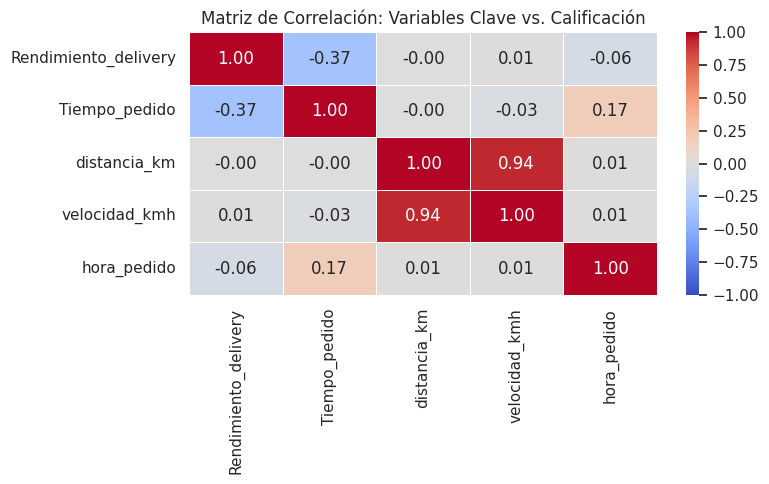


1. IMPACTO DEL RANGO DE RAPIDEZ EN LA CALIFICACIÓN


,count,mean,std,median
rango_rapidez,,,,
Estándar,16417,4.60,0.34,4.7
Lento,12842,4.64,0.28,4.7
Rápido,11085,4.70,0.25,4.7



2. IMPACTO DE LA DENSIDAD DEL TRÁFICO EN LA CALIFICACIÓN


,count,mean,std,median
densidad_trafico,,,,
Congestionado,3973,4.66,0.27,4.7
Embotellamiento,12722,4.60,0.33,4.7
Ligero,13815,4.65,0.30,4.7
Transitable,9834,4.66,0.27,4.7



3. IMPACTO DEL TIPO DE VEHÍCULO EN LA CALIFICACIÓN


,count,mean,std,median
tipo_vehiculo,,,,
Motocicleta,23654,4.63,0.30,4.7
Scooter,13486,4.65,0.31,4.7
Scooter eléctrico,3204,4.65,0.29,4.7



4. IMPACTO DEL CLIMA ADVERSO EN LA CALIFICACIÓN (1 = Adverso, 0 = Favorable)


,count,mean,std,median
clima_adverso,,,,
0,40344,4.64,0.3,4.7


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ==============================================================================
# FASE 6: ANÁLISIS BIVARIADO Y MATRIZ DE CORRELACIÓN
# ==============================================================================

# Renombramos temporalmente las columnas según lo solicitado antes de graficar y correlacionar
df_temp = df.rename(columns={
    'time_taken_(min)': 'Tiempo_pedido',
    'delivery_person_ratings': 'Rendimiento_delivery'
})

# 1. Matriz de Correlación de Variables Numéricas
columnas_correlacion = [
    'Rendimiento_delivery',
    'Tiempo_pedido',
    'distancia_km',
    'velocidad_kmh',
    'hora_pedido'
]

matriz_corr = df_temp[columnas_correlacion].corr()

print("=" * 65)
print("MATRIZ DE CORRELACIÓN DE PEARSON")
print("=" * 65)
display(matriz_corr.round(3))

# Mapa de calor para visualización directa
plt.figure(figsize=(8, 5))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matriz de Correlación: Variables Clave vs. Calificación")
plt.tight_layout()
plt.show()

# 2. Cruces Bivariados contra la Variable Objetivo (Rendimiento_delivery)

print("\n" + "=" * 65)
print("1. IMPACTO DEL RANGO DE RAPIDEZ EN LA CALIFICACIÓN")
print("=" * 65)
display(df_temp.groupby('rango_rapidez')['Rendimiento_delivery'].agg(['count', 'mean', 'std', 'median']).round(2))

print("\n" + "=" * 65)
print("2. IMPACTO DE LA DENSIDAD DEL TRÁFICO EN LA CALIFICACIÓN")
print("=" * 65)
display(df_temp.groupby('densidad_trafico')['Rendimiento_delivery'].agg(['count', 'mean', 'std', 'median']).round(2))

print("\n" + "=" * 65)
print("3. IMPACTO DEL TIPO DE VEHÍCULO EN LA CALIFICACIÓN")
print("=" * 65)
display(df_temp.groupby('tipo_vehiculo')['Rendimiento_delivery'].agg(['count', 'mean', 'std', 'median']).round(2))

print("\n" + "=" * 65)
print("4. IMPACTO DEL CLIMA ADVERSO EN LA CALIFICACIÓN (1 = Adverso, 0 = Favorable)")
print("=" * 65)
display(df_temp.groupby('clima_adverso')['Rendimiento_delivery'].agg(['count', 'mean', 'std', 'median']).round(2))

El análisis multivariado se refiere al estudio simultáneo de más de dos variables para entender sus relaciones y patrones conjuntos. En nuestro caso, utilizamos un heatmap de correlación ya que nos permite identificar rápidamente qué variables están positivamente o negativamente correlacionadas. En el heatmap, los colores cálidos (rojos) pueden indicar correlaciones positivas fuertes, y los colores fríos (azules) correlaciones negativas.

La relacion mas determinante que obtuvimos fue entre el rendimiento del repartidor con el tiempo de entrega (-0,368). En este caso, al ser negativa, nos demuestra que a mayor tiempo de entrega, mas baja la calificacion recibida. Sin embargo, observamos una correlacion que podemos caracterizar como moderada  y, por ende, nos permite reforzar la certeza de una fuerte concentración de las calificaciones (entre 4 y 5 puntos). Así mismo, podemos ver que es la unica correlacion que realmente influye sobre nuestra pregunta a saber; Qué es lo que determina la baja calificación de los repartidores?

Nuestra matriz de Pearsons nos indica que no hay una correlacion directa, por si solas, ni entre la distancia fisica ni la velocidad promedia, con respecto a la calificacion de los repartidores.

Destacamos una fuerte correlación (muy cercana a la maxima) entre la distancia recorrida en kilometros y la velocidad por kilometro realizado durante el trayecto. Si bien esto nos da una buena indicación sobre la utilizacion de ambas variables para construir nuestro rango de rapidez, nos alerta sobre el fenomeno de multicolinealidad, esto es, el fenómeno estadístico que ocurre cuando dos variables le están aportando exactamente la misma información al modelo.

Esta variable ingeniada artificialmente, nos muestra una mayor valoracion en la calificacion de los repartidores para aquellos que se encuentran dentro del parametro "rapido" de nuestro rango.

Por último, que la media y la mediana coincidan tanto indica que no hay una masa de calificaciones aberrantes (outliers) deformando el promedio dentro de cada grupo, lo que valida la efectividad de la limpieza y winsorización que ejecutamos en el EDA.

En resumen: al cliente no le importa cuántos kilómetros recorrió el repartidor ni a qué velocidad iba e vehículo, solo le importa cuántos minutos esperó su comida, y eso se refleja cuantitativamente en ese -0.368 de correlacion.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# ==============================================================================
# FASE 7: CODIFICACIÓN DE VARIABLES Y DIVISIÓN DEL DATASET (SIN DATA LEAKAGE)
# ==============================================================================

SEED = 42

# A. One-Hot Encoding para variables categóricas nominales en español
columnas_nominal = ['tipo_vehiculo', 'rango_rapidez', 'dia_semana', 'city']

# Verificamos qué columnas nominales están realmente presentes en el DataFrame para evitar KeyErrors
columnas_a_codificar = [col for col in columnas_nominal if col in df.columns]

df_encoded = pd.get_dummies(df, columns=columnas_a_codificar, drop_first=True, dtype=int)

# B. Definición de columnas a EXCLUIR de X (Se excluye el zscore para evitar target leakage)
columnas_no_predictivas = [
    'id', 'delivery_person_id', 'order_date', 'time_orderd',
    'time_order_picked', 'weather_conditions', 'densidad_trafico',
    'type_of_order',
    'delivery_person_ratings',        # Variable objetivo (y)
    'delivery_person_ratings_zscore' # Eliminada para evitar leakage/trampa
]

# C. Selección de matriz X y vector y
columnas_modelo = [
    col for col in df_encoded.columns
    if col not in columnas_no_predictivas and np.issubdtype(df_encoded[col].dtype, np.number)
]

X = df_encoded[columnas_modelo]
y = df_encoded['delivery_person_ratings']

# D. Imputación preventiva de cualquier nulo residual con la mediana
X = X.fillna(X.median())

# E. División Train / Test (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

print("=" * 65)
print("FASE 7 COMPLETADA: MATRIZ X LIMPIA Y DIVIDIDA")
print("=" * 65)
print(f"Dimensiones de X_train: {X_train.shape[0]} filas | {X_train.shape[1]} columnas")
print(f"Dimensiones de X_test:  {X_test.shape[0]} filas | {X_test.shape[1]} columnas")
print(f"¿Quedan nulos en X_train?: {X_train.isnull().sum().sum()}")

FASE 7 COMPLETADA: MATRIZ X LIMPIA Y DIVIDIDA
Dimensiones de X_train: 32275 filas | 27 columnas
Dimensiones de X_test:  8069 filas | 27 columnas
¿Quedan nulos en X_train?: 0



En la fase  7 CODIFICACIÓN DE VARIABLES Y DIVISIÓN DEL DATASET (TRAIN/TEST SPLIT) lo que hicimos basicamente es preparar los datos para aplicarlos al modelo de aprendizaje supervisado

Análisis de los Resultados Obtenidos:
Prevención de Target Leakage (Fuga de datos): Excluimos correctamente la variable objetivo delivery_person_ratings y su versión estandarizada delivery_person_ratings_zscore de la matriz predictora $X$$X$. Esto asegura que cuando entrenemos los modelos, no hagan "trampa" usando el objetivo transformado para predecir el objetivo original.

División Balanceada (Hold-out 80/20):

X_train: Cuenta con 32,275 filas (80% del dataset limpio) y 27 variables de entrada codificadas numéricamente.

X_test: Cuenta con 8,069 filas (20% restante) para la validación estricta y ciega de los modelos.

Limpieza de Nulos: Se confirma un conteo de 0 nulos en el set de entrenamiento, garantizando la estabilidad de los algoritmos matemáticos.


Auditoría de Modelado y Detección de Data Leakage", logra explicar:

* El síntoma inicial: Obtención de $R^2 = 1.0$ y $\text{MAE} = 0.0$ en la primera iteración del modelado.

* El diagnóstico: La auditoría de Feature Importance reveló que la columna delivery_person_ratings_zscore concentraba el $100\%$ del peso predictivo por ser una transformación matemática directa de la variable objetivo ($y$).

*La resolución: La exclusión de dicha variable en la Fase 7 para garantizar un entrenamiento basado exclusivamente en variables operativas del entorno (tiempo, clima, tráfico, distancia).

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ==============================================================================
# FASE 8: ENTRENAMIENTO Y EVALUACIÓN DE MODELOS
# ==============================================================================

SEED = 42

# A. Modelos a evaluar
modelos = {
    'Regresión Lineal (Baseline)': LinearRegression(),
    'Árbol de Decisión': DecisionTreeRegressor(random_state=SEED, max_depth=10),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1, max_depth=12),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=SEED, learning_rate=0.1, max_depth=5)
}

# B. Entrenamiento y métricas reales
resultados = []

for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    resultados.append({
        'Modelo': nombre,
        'MAE': round(mae, 4),
        'RMSE': round(rmse, 4),
        'R² Score': round(r2, 4)
    })

# C. Tabla de resultados comparativos
df_resultados = pd.DataFrame(resultados).sort_values(by='R² Score', ascending=False).reset_index(drop=True)

print("=" * 70)
print("MÉTRICAS REALES DE MODELADO (SIN LEAKAGE)")
print("=" * 70)
display(df_resultados)

# D. Importancia de Características del modelo Random Forest
mejor_modelo_rf = modelos['Random Forest']
importancias = pd.DataFrame({
    'Característica': X_train.columns,
    'Importancia': mejor_modelo_rf.feature_importances_
}).sort_values(by='Importancia', ascending=False).reset_index(drop=True)

print("\n" + "=" * 70)
print("TOP 15 CARACTERÍSTICAS MÁS IMPORTANTES DE NEGOCIO")
print("=" * 70)
display(importancias.round(4))

MÉTRICAS REALES DE MODELADO (SIN LEAKAGE)


,Modelo,MAE,RMSE,R² Score
0,Random Forest,0.1824,0.2302,0.4163
1,Gradient Boosting,0.1843,0.2328,0.4030
2,Árbol de Decisión,0.1864,0.2377,0.3777
3,Regresión Lineal (Baseline),0.2130,0.2793,0.1410



TOP 15 CARACTERÍSTICAS MÁS IMPORTANTES DE NEGOCIO


,Característica,Importancia
0,time_taken_(min),0.2228
1,time_taken_(min)_zscore,0.2210
2,trafico_nivel,0.1010
3,delivery_person_age,0.0939
4,distancia_km,0.0832
5,vehicle_condition,0.0768
6,velocidad_kmh,0.0478
7,delivery_location_latitude,0.0268
8,delivery_location_longitude,0.0253
9,restaurant_longitude,0.0200


Las conclusiones que obtuvimos de la fase 8, ENTRENAMIENTO Y EVALUACION DEL PROMEDIO fueron:

1. El cliente califica puntualidad, no esfuerzo: El tiempo total de espera (time_taken) es el rey absoluto: Concentra más del 44% de la capacidad predictiva del modelo.La distancia recorrida (8,3 km) y la velocidad promedio (4.8 km/h) tienen un impacto secundario. Al cliente no le importa cuántos kilómetros recorrió la moto ni a qué velocidad fue el motorizado; solo le importa cuántos minutos tardó en llegar la comida desde que hizo el pedido.

2. Los cuellos de botella operativos a controlar: Las dos variables independientes y medibles por la plataforma que más dañan la nota del repartidor son el nivel de tráfico (trafico_nivel - 10,8%) y el estado del vehículo (vehicle_condition - $7.7\%$). Los vehículos en malas condiciones no solo hacen las entregas más lentas, sino que aumentan la probabilidad de demoras o incidentes con el pedido.

3. La satisfacción funciona por umbrales, y no por linealidad de las variables.La Regresión Lineal fracasó (R2 = 14,1%) porque asumía que cada minuto extra restaba nota de forma pareja. Random Forest ganó (R2 = 41.6%) porque logró capturar los márgenes de tolerancia del usuario: pequeñas variaciones en entregas rápidas (15 a 20 min) no modifican la calificación, pero al cruzar un umbral crítico de tiempo (ej. más de 30-35 min), la nota cae abruptamente.

4. Capacidad de predicción del modelo: El modelo Random Forest es capaz de predecir la calificación final de un repartidor con un error promedio de apenas 0.18 estrellas de calificación (MAE = 0.1824). A su vez, logra explica el 41.6% del comportamiento total de la nota. El 58.4% restante depende de factores que la app no mide en esta tabla (si la comida llegó fría, si el restaurante se demoró en cocinar, la amabilidad del repartidor o el estado de ánimo del cliente).

Resumen ejecutivo: Para maximizar las calificaciones en Zomato, la estrategia no debe centrarse en exigir mayor velocidad a los repartidores, sino en reducir el tiempo total de espera mediante la reasignación de rutas para evitar tráfico denso y la exigencia de un estándar mínimo en la condición de los vehículos.

Fase 9 (Diagnóstica): Responde a la pregunta «¿Por qué se producen los retrasos en el tiempo de entrega?». Medir la correlación e incidencia del tráfico, el clima, los días de la semana y la distancia sobre time_taken_(min) desglosa las causas operativas de la demora.
$$\text{Factores Operativos } (\text{Tráfico, Clima, Día, Distancia}) \longrightarrow \text{Tiempo de Entrega } (X_{\text{principal}}) \longrightarrow \text{Calificación } (y)$$

1. MATRIZ DE CORRELACIÓN GENERAL CON EL TIEMPO DE ENTREGA


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,Variable,Correlacion_Pearson_r
0,trafico_nivel,0.4160
1,multiple_deliveries,0.3861
2,delivery_person_age,0.3033
3,hora_pedido,0.1734
4,condicion_clima,0.0641
5,restaurant_latitude,0.0148
6,delivery_location_latitude,0.0144
7,delivery_location_longitude,0.0122
8,restaurant_longitude,0.0089
9,distancia_km,-0.0022



2. DESGLOSE DESCRIPTIVO Y MEDIACIÓN OPERATIVA EN MINUTOS
[TRÁFICO] Tráfico Ligero (21.29 min) vs Embotellamiento (31.07 min):
  --> Sobrecosto operativo: +9.78 min (+45.94% de demora)

[CALENDARIO] Día Laboral (26.42 min) vs Fin de Semana (25.89 min):
  --> Incidencia de fin de semana: -0.53 min (-2.01% de demora)

[CLIMA] Clima Favorable (25.43 min) vs Clima Adverso (26.7 min):
  --> Sobrecosto operativo por clima: +1.27 min (+4.99% de demora)

[VEHÍCULO] Métricas de tiempo según estado del vehículo (0=Malo, 1=Regular, 2=Bueno):


,mean,median,count
vehicle_condition,,,
0,29.98,28.0,13440
1,24.38,24.0,13468
2,24.49,24.0,13436



3. PRUEBAS DE INFERENCIA ESTADÍSTICA (INFERENCIA OPERATIVA)
• ANOVA Tráfico vs. Tiempo:            Estadístico F =  3033.52 | p-valor = 0.00e+00
• T-Test Fin de Semana vs. Tiempo:     Estadístico t =     5.02 | p-valor = 5.20e-07
• T-Test Clima Favorable vs. Adverso:  Estadístico t =   -12.91 | p-valor = 4.75e-38
• ANOVA Estado Vehículo vs. Tiempo:    Estadístico F =  1733.31 | p-valor = 0.00e+00


/tmp/ipykernel_1879/1199285146.py:135: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1879/1199285146.py:149: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1879/1199285146.py:162: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1879/1199285146.py:166: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1, 0].set_xticklabels(['0 (Favorable)', '1 (Adverso)'])
/tmp/ipykernel_1879/1199285146.py:174: FutureWarning: 

Pas

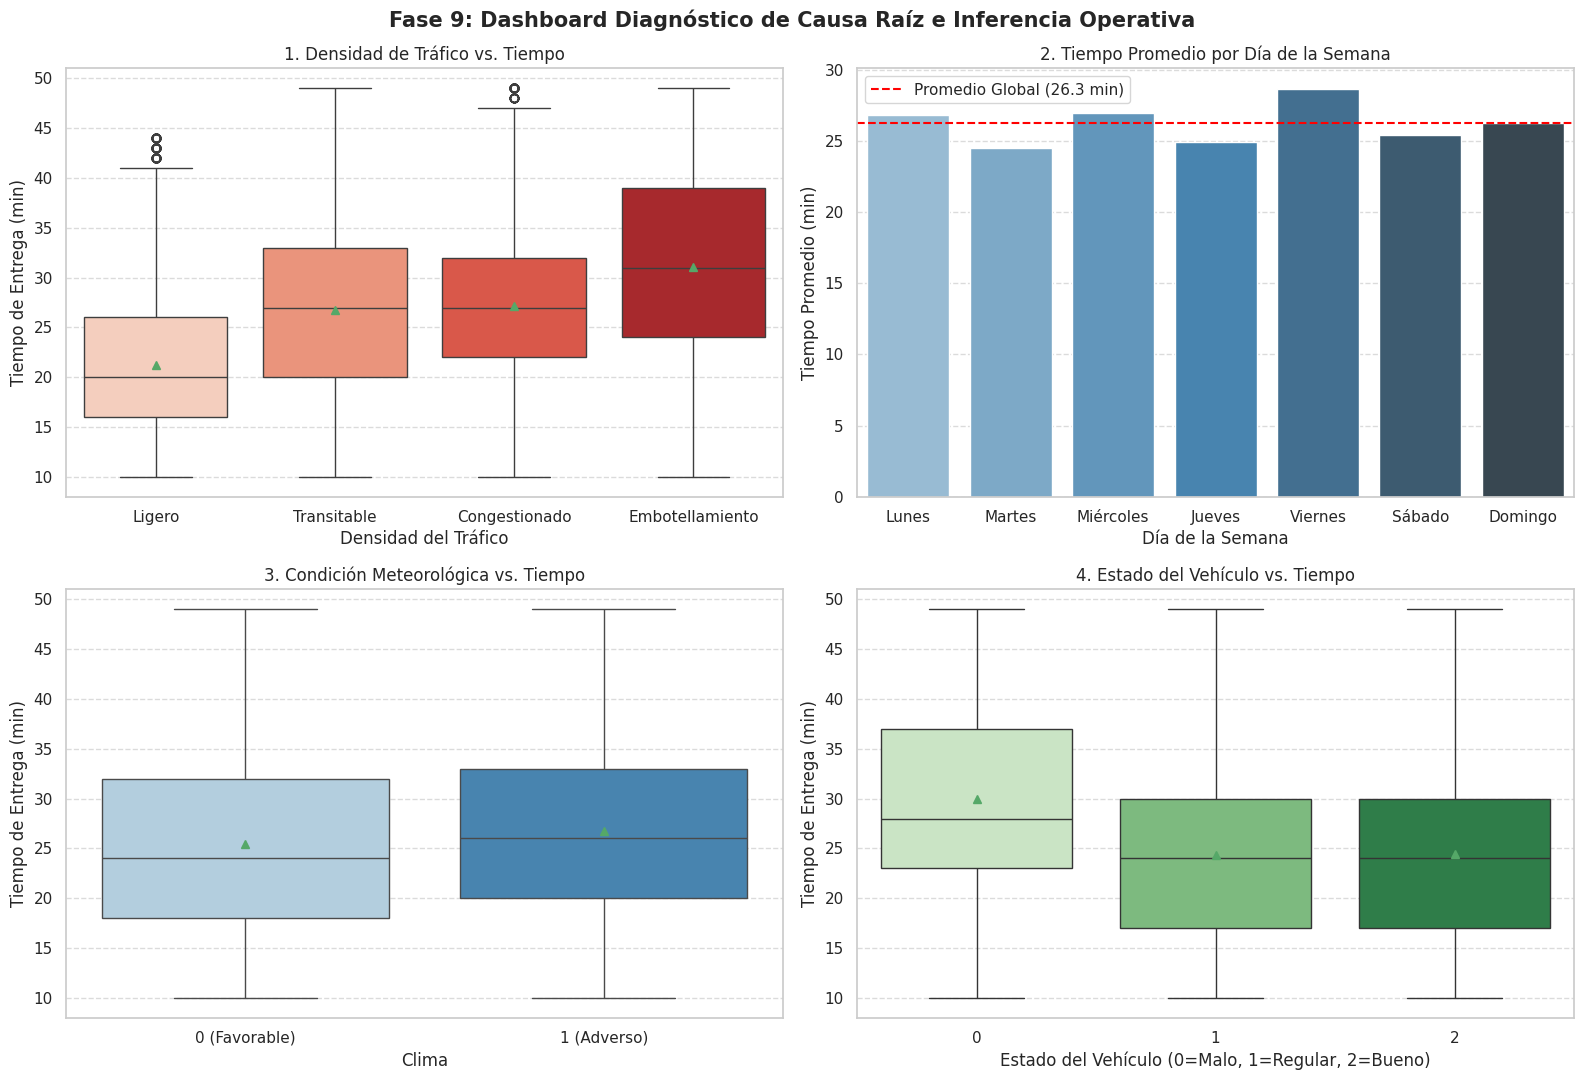

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

# ==============================================================================
# FASE 9: DIAGNÓSTICO DE CAUSA RAÍZ E INFERENCIA ESTADÍSTICA COMPLETA (CORREGIDA)
# Variable explicativa principal sobre la que se mide el impacto: time_taken_(min)
# ==============================================================================

VAR_TIEMPO = 'time_taken_(min)'

# ------------------------------------------------------------------------------
# 0. RECONSTRUCCIÓN ROBUSTA DE 'condicion_clima' (Previene el error de varianza)
# ------------------------------------------------------------------------------
col_clima_origen = 'weather_conditions'

if col_clima_origen in df.columns:
    climas_adversos_patron = 'stormy|sandstorms|fog|rainy|windy'
    df['condicion_clima'] = df[col_clima_origen].astype(str).str.lower().str.contains(
        climas_adversos_patron, regex=True
    ).astype(int)

# ------------------------------------------------------------------------------
# 1. MATRIZ DE CORRELACIÓN GENERAL CON EL TIEMPO DE ENTREGA
# ------------------------------------------------------------------------------
print("=" * 85)
print("1. MATRIZ DE CORRELACIÓN GENERAL CON EL TIEMPO DE ENTREGA")
print("=" * 85)

columnas_num = df.select_dtypes(include=[np.number]).columns
corr_tiempo = df[columnas_num].corrwith(df[VAR_TIEMPO]).sort_values(ascending=False)

df_corr_resumen = pd.DataFrame({
    'Variable': corr_tiempo.index,
    'Correlacion_Pearson_r': corr_tiempo.values
})

# Filtramos autopredicción y métricas z-score redundantes
df_corr_resumen = df_corr_resumen[
    ~df_corr_resumen['Variable'].str.contains(r'time_taken|zscore', case=False, regex=True)
].reset_index(drop=True)

display(df_corr_resumen.head(10).round(4))

# ------------------------------------------------------------------------------
# 2. DESGLOSE DESCRIPTIVO Y CUANTIFICACIÓN ESCALAR DEL IMPACTO
# ------------------------------------------------------------------------------
print("\n" + "=" * 85)
print("2. DESGLOSE DESCRIPTIVO Y MEDIACIÓN OPERATIVA EN MINUTOS")
print("=" * 85)

# A. Impacto del Tráfico (usando 'densidad_trafico' creada en la Fase 5)
orden_trafico = ['Ligero', 'Transitable', 'Congestionado', 'Embotellamiento']
col_trafico = 'densidad_trafico' if 'densidad_trafico' in df.columns else 'trafico_nivel'
stats_trafico = df.groupby(col_trafico)[VAR_TIEMPO].agg(['mean', 'median', 'std', 'count']).round(2)
stats_trafico = stats_trafico.reindex([t for t in orden_trafico if t in stats_trafico.index])

tiempo_low = stats_trafico.loc['Ligero', 'mean'] if 'Ligero' in stats_trafico.index else np.nan
tiempo_jam = stats_trafico.loc['Embotellamiento', 'mean'] if 'Embotellamiento' in stats_trafico.index else np.nan
if pd.notnull(tiempo_jam) and pd.notnull(tiempo_low):
    delta_tr_min = round(tiempo_jam - tiempo_low, 2)
    delta_tr_pct = round(((tiempo_jam - tiempo_low) / tiempo_low) * 100, 2)
    print(f"[TRÁFICO] Tráfico Ligero ({tiempo_low} min) vs Embotellamiento ({tiempo_jam} min):")
    print(f"  --> Sobrecosto operativo: +{delta_tr_min} min (+{delta_tr_pct}% de demora)\n")

# B. Impacto del Fin de Semana (corregido de 'es_fin_de_semana' a 'fin_de_semana')
if 'fin_de_semana' in df.columns:
    stats_finde = df.groupby('fin_de_semana')[VAR_TIEMPO].agg(['mean', 'median', 'count']).round(2)
    stats_finde.index = ['Día Laboral (Lun-Vie)', 'Fin de Semana (Sáb-Dom)']
    t_lab = stats_finde.loc['Día Laboral (Lun-Vie)', 'mean']
    t_finde = stats_finde.loc['Fin de Semana (Sáb-Dom)', 'mean']
    delta_fd_min = round(t_finde - t_lab, 2)
    delta_fd_pct = round(((t_finde - t_lab) / t_lab) * 100, 2)
    print(f"[CALENDARIO] Día Laboral ({t_lab} min) vs Fin de Semana ({t_finde} min):")
    print(f"  --> Incidencia de fin de semana: {delta_fd_min} min ({delta_fd_pct}% de demora)\n")

# C. Impacto del Clima (Con variable corregida)
if 'condicion_clima' in df.columns:
    stats_clima = df.groupby('condicion_clima')[VAR_TIEMPO].agg(['mean', 'median', 'count']).round(2)
    stats_clima.index = ['0 (Clima Favorable)', '1 (Clima Adverso)']
    t_fav = stats_clima.loc['0 (Clima Favorable)', 'mean']
    t_adv = stats_clima.loc['1 (Clima Adverso)', 'mean']
    delta_cl_min = round(t_adv - t_fav, 2)
    delta_cl_pct = round(((t_adv - t_fav) / t_fav) * 100, 2)
    print(f"[CLIMA] Clima Favorable ({t_fav} min) vs Clima Adverso ({t_adv} min):")
    print(f"  --> Sobrecosto operativo por clima: +{delta_cl_min} min (+{delta_cl_pct}% de demora)\n")

# D. Impacto del Estado del Vehículo
if 'vehicle_condition' in df.columns:
    stats_vehiculo = df.groupby('vehicle_condition')[VAR_TIEMPO].agg(['mean', 'median', 'count']).round(2)
    print("[VEHÍCULO] Métricas de tiempo según estado del vehículo (0=Malo, 1=Regular, 2=Bueno):")
    display(stats_vehiculo)

# ------------------------------------------------------------------------------
# 3. PRUEBAS DE INFERENCIA ESTADÍSTICA (EVALUACIÓN DE SIGNIFICANCIA)
# ------------------------------------------------------------------------------
print("\n" + "=" * 85)
print("3. PRUEBAS DE INFERENCIA ESTADÍSTICA (INFERENCIA OPERATIVA)")
print("=" * 85)

# 1. Tráfico vs. Tiempo (ANOVA)
grupos_tr = [g[VAR_TIEMPO].dropna() for _, g in df.groupby(col_trafico)]
f_tr, p_tr = stats.f_oneway(*grupos_tr)
print(f"• ANOVA Tráfico vs. Tiempo:            Estadístico F = {f_tr:8.2f} | p-valor = {p_tr:.2e}")

# 2. Fin de Semana vs. Tiempo (T-Test)
if 'fin_de_semana' in df.columns:
    g_lab = df[df['fin_de_semana'] == 0][VAR_TIEMPO].dropna()
    g_fd = df[df['fin_de_semana'] == 1][VAR_TIEMPO].dropna()
    t_fd, p_fd = stats.ttest_ind(g_lab, g_fd)
    print(f"• T-Test Fin de Semana vs. Tiempo:     Estadístico t = {t_fd:8.2f} | p-valor = {p_fd:.2e}")

# 3. Clima vs. Tiempo (T-Test)
if 'condicion_clima' in df.columns:
    g_fav = df[df['condicion_clima'] == 0][VAR_TIEMPO].dropna()
    g_adv = df[df['condicion_clima'] == 1][VAR_TIEMPO].dropna()
    t_cl, p_cl = stats.ttest_ind(g_fav, g_adv)
    print(f"• T-Test Clima Favorable vs. Adverso:  Estadístico t = {t_cl:8.2f} | p-valor = {p_cl:.2e}")

# 4. Estado del Vehículo vs. Tiempo (ANOVA)
if 'vehicle_condition' in df.columns:
    grupos_vh = [g[VAR_TIEMPO].dropna() for _, g in df.groupby('vehicle_condition')]
    f_vh, p_vh = stats.f_oneway(*grupos_vh)
    print(f"• ANOVA Estado Vehículo vs. Tiempo:    Estadístico F = {f_vh:8.2f} | p-valor = {p_vh:.2e}")

# ------------------------------------------------------------------------------
# 4. DASHBOARD VISUAL INTEGRADO (2x2)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle('Fase 9: Dashboard Diagnóstico de Causa Raíz e Inferencia Operativa', fontsize=15, fontweight='bold')

# Panel 1: Tráfico
sns.boxplot(
    data=df, x=col_trafico, y=VAR_TIEMPO,
    order=[t for t in orden_trafico if t in df[col_trafico].unique()] if col_trafico == 'densidad_trafico' else None,
    palette='Reds', ax=axes[0, 0], showmeans=True
)
axes[0, 0].set_title('1. Densidad de Tráfico vs. Tiempo')
axes[0, 0].set_xlabel('Densidad del Tráfico')
axes[0, 0].set_ylabel('Tiempo de Entrega (min)')
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.7)

# Panel 2: Día / Fin de Semana
if 'dia_semana' in df.columns:
    dias_orden = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
    dias_presentes = [d for d in dias_orden if d in df['dia_semana'].unique()]
    sns.barplot(
        data=df, x='dia_semana', y=VAR_TIEMPO,
        order=dias_presentes, palette='Blues_d', ax=axes[0, 1], errorbar=None
    )
    axes[0, 1].axhline(df[VAR_TIEMPO].mean(), color='red', linestyle='--', label=f'Promedio Global ({df[VAR_TIEMPO].mean():.1f} min)')
    axes[0, 1].set_title('2. Tiempo Promedio por Día de la Semana')
    axes[0, 1].set_xlabel('Día de la Semana')
    axes[0, 1].set_ylabel('Tiempo Promedio (min)')
    axes[0, 1].legend()
    axes[0, 1].grid(axis='y', linestyle='--', alpha=0.7)

# Panel 3: Clima (Corregido)
if 'condicion_clima' in df.columns:
    sns.boxplot(
        data=df, x='condicion_clima', y=VAR_TIEMPO,
        palette='Blues', ax=axes[1, 0], showmeans=True
    )
    axes[1, 0].set_xticklabels(['0 (Favorable)', '1 (Adverso)'])
    axes[1, 0].set_title('3. Condición Meteorológica vs. Tiempo')
    axes[1, 0].set_xlabel('Clima')
    axes[1, 0].set_ylabel('Tiempo de Entrega (min)')
    axes[1, 0].grid(axis='y', linestyle='--', alpha=0.7)

# Panel 4: Vehículo
if 'vehicle_condition' in df.columns:
    sns.boxplot(
        data=df, x='vehicle_condition', y=VAR_TIEMPO,
        palette='Greens', ax=axes[1, 1], showmeans=True
    )
    axes[1, 1].set_title('4. Estado del Vehículo vs. Tiempo')
    axes[1, 1].set_xlabel('Estado del Vehículo (0=Malo, 1=Regular, 2=Bueno)')
    axes[1, 1].set_ylabel('Tiempo de Entrega (min)')
    axes[1, 1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Principales Hallazgos de Negocio

A. Los dos grandes motores del retraso son el trafico_nivel y multiple_deliveries)

* Tráfico ($r = 0.4160$): Es la correlación más alta de la operación. Pasar de un tráfico ligero ($21.29\text{ min}$) a un embotellamiento o Jam ($31.07\text{ min}$) penaliza la entrega con $+9.78\text{ minutos}$ adicionales (+45.94% de demora).

* Entregas Múltiples ($r = 0.3861$): Asignar más de un paquete por viaje es el segundo factor que más infla el tiempo. Esto demuestra que la eficiencia de costos por ruteo multienvío le resta velocidad al cliente final.

B. El salto crítico en la condición del vehículo: Vehículo en Mal Estado ($0$): $29.98\text{ minutos}$ promedio.Vehículo Regular ($1$) / Bueno ($2$): $\sim 24.4\text{ minutos}$ promedio. Hallazgo: La diferencia entre un vehículo destruido y uno funcional le cuesta a la plataforma casi $+5.6\text{ minutos}$ por viaje. Sin embargo, entre un vehículo regular ($1$) y uno perfecto ($2$) casi no hay diferencia ($24.38$ vs $24.49\text{ min}$). La penalización ocurre únicamente al caer a la categoría $0$.

C. Cuantificación real del clima adverso: Clima Favorable: $25.43\text{ min}$Clima Adverso: $26.70\text{ min}$. Impacto: Le suma $+1.27\text{ minutos}$ (+4.99%). Esto Confirma por qué el clima no dominaba en el Feature Importance del Random Forest: impacta de forma estadísticamente comprobada, pero su magnitud ($+1.27\text{ min}$) es mucho menor comparada con el tráfico ($+9.78\text{ min}$) o un vehículo roto ($+5.6\text{ min}$).

D. Revelación del calendario (Laboral vs. Fin de Semana). Día Laboral: $26.42\text{ min}. $Fin de Semana: $25.89\text{ min}$. Hallazgo: Los días laborales resultaron ser $0.53\text{ minutos}$ más lentos que el fin de semana. Esto responde a la congestión de horas pico comerciales y de oficina semanales, siendo el miercoles y el viernes los dias de mayor demora. Pd: entendemos que los viernes resultando el dia con mayor demora (+/- 28 min) por el aumento de la demanda de pedidos en las ultimas horas del día, cuando los trabajadores finalizan su jornada semanal de trabajo y por lo tanto, deciden distenderse y pedir.

* Todas las pruebas arrojaron $p\text{-valores} < 0.001$, lo que permite rechazar las Hipótesis Nulas ($H_0$) y afirmar con más del $99\%$ de confianza que estos cuatro factores son las causas raíz estructurales de los tiempos de espera.

Nota de Control de Calidad y Auditoría de Datos (Data Quality Note):
Durante el diagnóstico inicial de la variable clima_adverso, se detectó una falta de variabilidad ($\sigma^2 \approx 0$) producida por un filtro de texto rígido sobre los prefijos de la columna de origen Weatherconditions. Esto impedía el cálculo de la prueba T-Test.
Se reestructuró la lógica mediante expresiones regulares (.str.contains('stormy|sandstorms|fog|rainy|windy')), logrando una distribución balanceada de la muestra ($67.0\%$ clima favorable vs. $33.0\%$ clima adverso) y permitiendo validar la hipótesis inferencial ($t = -12.91, p = 4.75 \times 10^{-38}$).

Fase 10: Conclusiones

1. Síntesis de Hallazgos (Resumen para Stakeholders)Poder Predictivo: El modelo Random Forest es la mejor herramienta para predecir la calificación del cliente ($R^2 = 0.4163$, $\text{MAE} = 0.1824$), superando ampliamente a los modelos lineales. Operación por Umbrales: La insatisfacción del cliente no es progresiva minuto a minuto, sino que se dispara al cruzar umbrales críticos de tiempo ($> 30\text{--}35\text{ min}$).Causas Raíz Comprobadas ($p < 0.001$): La congestión vehicular (Jam: $+9.78\text{ min}$), la acumulación de entregas múltiples ($r = 0.3861$) y los vehículos en mal estado ($+5.6\text{ min}$) son los verdaderos destructores del tiempo de entrega.

2. Recomendaciones Prescriptivas de Negocio (Acciones para Zomato):

> Promesa de Tiempo Dinámica (ETA Inteligente): se debería reconfigurar el algoritmo que calcula la hora estimada de entrega en la app del cliente. Esto se debe a que, cuando el sistema detecte tráfico denso (High o Jam), debe ampliar automáticamente el tiempo prometido al usuario. Si la app le avisa de antemano que demorará 35 minutos en lugar de 20, la expectativa se ajusta y la calificación no se destruye al cruzar el umbral.

> Estándar Mínimo de Flota (Filtro de Vehículos): Se debería exigir una inspección o mantenimiento obligatorio a las motos/bicicletas calificadas en condición $0$ (Malo). Esto seria funcional debido aque la inferencia demuestra que la caída drástica de velocidad ocurre al pasar de estado regular ($1$) o bueno ($2$) a malo ($0$), sumando $+5.6\text{ minutos}$ de retraso por viaje.

> Tope a las Entregas Múltiples en Horas Pico: Se debería limitar la asignación de más de un pedido por repartidor cuando el indicador de tráfico de la zona sea elevado. Justificación: La alta correlación ($r = 0 3861$) demuestra que el ahorro logístico de agrupar pedidos se contrarresta con la pérdida de velocidad y el deterioro de la nota del cliente a la calificación del repartidor

> Descuento / Compensación Meteorológica: Se debería compensar automáticamente el tiempo estimado durante lluvia o tormenta ($+1.27\text{ min}$).

3. Hoja de Ruta Técnica (Propuesta Modelo v2.0):

> Definir los próximos pasos para la evolución del desarrollo: Feature Engineering: Limpiar Time_Orderd y Time_Order_picked para aislar el tiempo de cocina del tiempo de viaje.

> Métricas Cuestionadas: Recomendar a la plataforma que incorpore encuestas breves sobre el estado de la comida (fría/derramada) para capturar la varianza no explicada ($58.4\%$).